# TensorFlow: An example using Fashion MNIST 


## Start Coding

Let's first import TensorFlow

In [16]:
import tensorflow as tf

The Fashion MNIST data is available directly in the tf.keras datasets API. You load it like this:

In [17]:
fash_mnist = tf.keras.datasets.fashion_mnist

Calling load_data on this object will give you two sets of two lists, these will be the training and testing values for the graphics that contain the clothing items and their labels.


In [29]:
(training_images, training_labels), (test_images, test_labels) = fash_mnist.load_data()
print(training_images.shape)  # Should print (28, 28)
print(test_images.shape)  # Should print (28, 28)

(60000, 28, 28)
(10000, 28, 28)


Let’s visualize some of the training data to better understand what the values represent. We'll print both an image and its corresponding label to see how they look. You can try this with different indices in the dataset to explore various samples. For instance, let's take a look at index 42. You’ll notice that the boot at index 42 is quite different from the one at index 0, and this will help us understand how the model is learning to distinguish between them.

9
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   1   0   0  13  73   0   0   1   4   0   0   0   0   1   1   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3   0  36 136 127  62  54   0   0   0   1   3   4   0   0   3]
 [  0   0   0   0   0   0   0   0   0   0   0   0   6   0 102 204 176 134 144 123  23   0   0   0   0  12  10   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0 155 236 207 178 107 156 161 109  64  23  77 130  72  15]
 [  0   0   0   0   0   0   0   0   0   0   0   1   0  69 207 223 218 216 216 163 127 121 122 146 141  88 172  66]
 [  0   0   0   0   0   0   0   0   0   1   1   1   0 200 232 232 233 229 223 

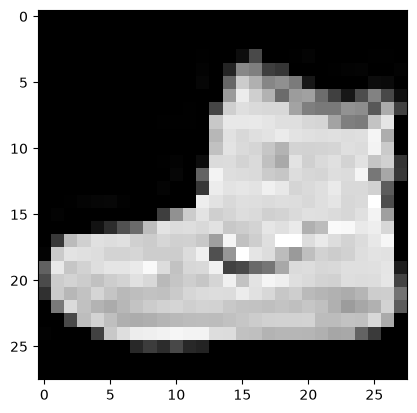

In [19]:
import numpy as np
np.set_printoptions(linewidth=200)
import matplotlib.pyplot as plt
plt.imshow(training_images[0], cmap='gray')
print(training_labels[0])
print(training_images[0])

You may notice that the pixel values in the image range from 0 to 255. However, when training a neural network, it's often more efficient to normalize these values so that they fall within a range of 0 to 1. This process is called **normalization**, and it can help improve the training performance and stability of the model. The good news is that normalizing an array in Python is straightforward, and we can do it without needing to write a loop. Here's how you can normalize the values:

In [20]:
training_images  = training_images / 255.0
test_images = test_images / 255.0

We have 2 sets...training and testing -- The idea is to have one set of data for training, and then another set of data...that the model hasn't yet seen...to see how good it would be at classifying values. After all, when you're done, you're going to want to try it out with data that it hadn't previously seen!

Let's now design the model. There's quite a few new concepts here... 

In [21]:
model = tf.keras.models.Sequential([tf.keras.layers.Flatten(), 
                                    tf.keras.layers.Dense(128, activation=tf.nn.relu), 
                                    tf.keras.layers.Dense(10, activation=tf.nn.softmax)])


**Sequential**: That defines a SEQUENCE of layers in the neural network

**Flatten**: Remember earlier where our images were a square, when you printed them out? Flatten just takes that square and turns it into a 1 dimensional set.

**Dense**: Adds a layer of neurons

Each layer of neurons need an **activation function** to tell them what to do. There's lots of options, but just use these for now. 

**Relu** effectively means "If X>0 return X, else return 0" -- so what it does it it only passes values 0 or greater to the next layer in the network.

**Softmax** takes a set of values, and effectively picks the biggest one, so, for example, if the output of the last layer looks like [0.1, 0.1, 0.05, 0.1, 9.5, 0.1, 0.05, 0.05, 0.05], it saves you from fishing through it looking for the biggest value, and turns it into [0,0,0,0,1,0,0,0,0] -- The goal is to save a lot of coding!


The next thing to do, now the model is defined, is to actually build it. You do this by compiling it with an optimizer and loss function as before -- and then you train it by calling **model.fit ** asking it to fit your training data to your training labels -- i.e. have it figure out the relationship between the training data and its actual labels, so in future if you have data that looks like the training data, then it can make a prediction for what that data would look like. 

In [22]:
model.compile(optimizer = tf.optimizers.SGD(),
              loss = 'sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(training_images, training_labels, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 710us/step - accuracy: 0.7567 - loss: 0.7503
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 635us/step - accuracy: 0.8252 - loss: 0.5163
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 601us/step - accuracy: 0.8383 - loss: 0.4700
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 576us/step - accuracy: 0.8459 - loss: 0.4433
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 708us/step - accuracy: 0.8533 - loss: 0.4251
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 658us/step - accuracy: 0.8570 - loss: 0.4110
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 593us/step - accuracy: 0.8604 - loss: 0.3994
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 591us/step - accuracy: 0.8639 - loss: 0.3890
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 642us/step - accuracy: 0.8677 - loss: 0.3807
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 1s 647us/step - accuracy: 0.8701 - loss: 0.3717


Once it's done training -- you should see an accuracy value at the end of the final epoch. It might look something like 0.9098. This tells you that your neural network is about 91% accurate in classifying the training data. This is, it figured out a pattern match between the image and the labels that worked 91% of the time. Not great, but not bad considering it was only trained for 5 epochs and done quite quickly.

But how would it work with unseen data? That's why we have the test images. We can call model.evaluate. It will report back the loss and the accuracy. Let's give it a try:

In [23]:
model.evaluate(test_images, test_labels)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 533us/step - accuracy: 0.8556 - loss: 0.4082


[0.40820735692977905, 0.8555999994277954]

#### Model summary

To have a summary of the model architecture, you can use "model.summary()"

In [24]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (32, 784)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 128)              │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (32, 10)               │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,772 (397.55 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [25]:
# common code
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(linewidth=200)

mnist = tf.keras.datasets.fashion_mnist
(training_images, training_labels), (test_images, test_labels) = mnist.load_data()

training_images  = training_images / 255.0
test_images = test_images / 255.0

# To do 

- "Play" with the model: Try different values/configurations of the hyper-parameters and keep track of the obtained results.
- Introduce the validation set: 15 % of the training dataset: by adding parameter 'validation_split=0.15'to the function 'model.fit'

### Report the obtained performance here:

##### 10 epochs => 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

##### 15 epochs => 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

Epoch 1/10


/Users/skout/ENSIA/Y4/S7/DL/LABS/.venv/lib/python3.12/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 788us/step - accuracy: 0.1176 - loss: 143.4730 - val_accuracy: 0.1014 - val_loss: 2.2951
Epoch 2/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 755us/step - accuracy: 0.1277 - loss: 2.2477 - val_accuracy: 0.1317 - val_loss: 2.2257
Epoch 3/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 707us/step - accuracy: 0.1110 - loss: 2.2838 - val_accuracy: 0.1278 - val_loss: 2.2379
Epoch 4/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 691us/step - accuracy: 0.1309 - loss: 2.2395 - val_accuracy: 0.1300 - val_loss: 2.2156
Epoch 5/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 734us/step - accuracy: 0.1438 - loss: 2.2053 - val_accuracy: 0.1374 - val_loss: 2.2020
Epoch 6/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 699us/step - accuracy: 0.1161 - loss: 2.2806 - val_accuracy: 0.1061 - val_loss: 2.2757
Epoch 7/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 709us/step - accuracy: 0.1061 - loss: 2.2910 - val_accuracy: 0.1060 - val_loss: 2.2815
Epoch 8/10
1594/1594 ━━━━━━━━━━━━━━━━━━━━ 1s 702us/step - accuracy: 0.1253 - loss: 2.

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,772 (397.55 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 476us/step - accuracy: 0.1372 - loss: 2.2102


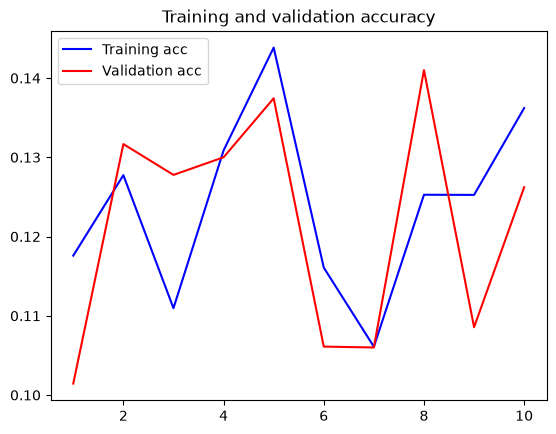

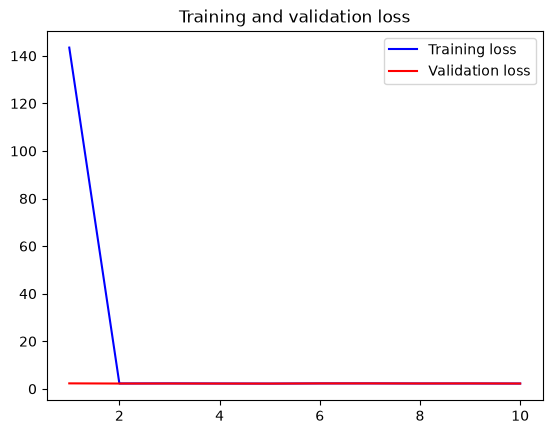

In [30]:
# Exp 1

# Here, we work with a two-layer NN.
# Learning is performaed using SGD, with a learning rate of 0.01 and momentum = 0

model = tf.keras.models.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(optimizer='sgd', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history = model.fit(training_images, training_labels, epochs=10, validation_split=0.15)

model.summary()

model.evaluate(test_images, test_labels)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()


# To do 

- Change the optimizer from 'SGD' to 'adam' in the function 'model.compile(...)'...

### Report the obtained performance here:

##### 15 epochs => 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

##### What do you think of the variance?
...

In [ ]:
# Exp 2

# Change the optimizer from 'SGD' to 'adam' in the function 'model.compile(...)'...

model = tf.keras.models.Sequential(...)

model.compile(...)

history = model.fit(...)

model.summary()

model.evaluate(test_images, test_labels)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()


# To do 

- In the previous experiment, we can notice a high variance.
- Use dropout to fix the problem. You can add layer "tf.keras.layers.Dropout(0.2)" before the hidden layer.

### Report the obtained performance here:

##### 15 epochs => 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

##### Does the dropout fix the problem?
...

In [ ]:
# Exp 3

model = tf.keras.models.Sequential(...)

model.compile(...)

history = model.fit(...)

model.summary()

model.evaluate(test_images, test_labels)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()


# To do 

- In the previous experiment, we have fixed the overfitting problem using dropout. Let's try to improve the accuracy of the model.
- Increase the number of neurons in the hidden layer => 512, 1024

### Report the obtained performance here:

##### 15 epochs for "512 hidden neurons"=> 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

##### 15 epochs for "1024 hidden neurons"=> 
- Train accuracy = ...
- Validation acc = ...
- Test acc = ...

##### Is it satisfying?
...

In [ ]:
# Exp 4

model = tf.keras.models.Sequential(...)

model.compile(...)

history = model.fit(...)

model.summary()

model.evaluate(test_images, test_labels)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()

# 15 epochs => 
# Train accuracy = 0.90
# Validation acc = 0.89
# Test acc = 0.89


# To do 

- Let's try to improve the performance by adding another hidden layer.
- So, we wil use two hidden layers (512, 128). For each layer, use dropout with a rate of 0.2.

### Report the obtained performance here:

##### 15 epochs => 
- Train accuracy = 
- Validation acc = 
- Test acc = 

##### Is it satisfying?
...

In [ ]:
# Exp 5

model = tf.keras.models.Sequential(...)

model.compile(...)

history = model.fit(...)

model.summary()

model.evaluate(test_images, test_labels)


acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.plot(epochs, acc, 'b', label='Training acc')
plt.plot(epochs, val_acc, 'r', label='Validation acc')
plt.title('Training and validation accuracy')
plt.legend()
plt.figure()

plt.plot(epochs, loss, 'b', label='Training loss')
plt.plot(epochs, val_loss, 'r', label='Validation loss')
plt.title('Training and validation loss')
plt.legend()

plt.show()


# Final report
...